In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel
import numpy as np

# Device
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Using device:", device)

# Load preprocessed dataset
from datasets import load_from_disk

processed_dataset = load_from_disk(
    "../data/processed/scienceqa_preprocessed"
)

# Load pretrained BERT
BERT_MODEL = "bert-base-uncased"

bert = AutoModel.from_pretrained(BERT_MODEL)

# Freeze BERT
for param in bert.parameters():
    param.requires_grad = False

bert = bert.to(device)
bert.eval()

print("BERT loaded and frozen.")

Using device: mps


W1110 22:08:55.177000 6983 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded and frozen.


### Prepare PyTorch datasets

In [2]:
class ScienceQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        return {
            "input_ids": torch.tensor(
                sample["input_ids"], dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                sample["attention_mask"], dtype=torch.long
            ),
            "option_mask": torch.tensor(
                sample["option_mask"], dtype=torch.bool
            ),
            "labels": torch.tensor(
                sample["labels"], dtype=torch.long
            )
        }


train_dataset = ScienceQADataset(processed_dataset["train"])
val_dataset = ScienceQADataset(processed_dataset["validation"])
test_dataset = ScienceQADataset(processed_dataset["test"])

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 442
Validation batches: 168
Test batches: 253


### Building the Text-Only BERT Baseline

This cell builds the text-only BERT model. I kept the pretrained BERT model frozen and added a linear layer to score each answer option. The model uses the question and answer text to identify the most suitable answer.

In [4]:
class TextOnlyBERT(nn.Module):
    def __init__(self, bert):
        super().__init__()

        self.bert = bert
        self.scorer = nn.Linear(768, 1)

        # Keep BERT frozen
        for param in self.bert.parameters():
            param.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        self.bert.eval()
        return self

    def forward(self, input_ids, attention_mask, option_mask):
        batch_size, num_choices, seq_length = input_ids.shape

        # Flatten the question-option inputs
        input_ids = input_ids.view(-1, seq_length)
        attention_mask = attention_mask.view(-1, seq_length)
        valid_options = option_mask.view(-1)

        # Process only real answer options
        valid_indices = valid_options.nonzero(as_tuple=True)[0]

        with torch.no_grad():
            outputs = self.bert(
                input_ids=input_ids[valid_indices],
                attention_mask=attention_mask[valid_indices]
            )

            cls_embeddings = outputs.last_hidden_state[:, 0, :]

        # Score each valid option
        valid_scores = self.scorer(cls_embeddings).squeeze(-1)

        # Restore the original batch and option dimensions
        scores = torch.full(
            (batch_size * num_choices,),
            float("-inf"),
            device=input_ids.device
        )

        scores[valid_indices] = valid_scores

        return scores.view(batch_size, num_choices)


model = TextOnlyBERT(bert).to(device)

print("Text-only BERT model created.")

Text-only BERT model created.


### Testing the Model Architecture

This cell checks whether the model is working correctly before training. It tests one batch of data and checks the input and output shapes, along with the scores generated for each answer option.

In [5]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
option_mask = batch["option_mask"].to(device)

with torch.no_grad():
    logits = model(input_ids, attention_mask, option_mask)

print("Input shape:", input_ids.shape)
print("Output shape:", logits.shape)
print("Sample logits:", logits[0])
print("All logits finite for valid options:",
      torch.isfinite(logits[option_mask]).all().item())

Input shape: torch.Size([8, 5, 128])
Output shape: torch.Size([8, 5])
Sample logits: tensor([0.1243, 0.0993, 0.2249, 0.1680,   -inf], device='mps:0')
All logits finite for valid options: True


### Setting Up Training

This cell defines the loss function and optimizer. Cross-entropy loss measures how well the model predicts the correct answer, while AdamW updates the trainable scoring layer to improve its predictions. BERT remains frozen during training.

In [6]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer (only trainable parameters)
optimizer = torch.optim.AdamW(
    model.scorer.parameters(),
    lr=1e-3,
    weight_decay=0.01
)

print("Loss function and optimizer configured.")

Loss function and optimizer configured.


### Training the Model

This function trains the model using the training data. It compares the predicted answers with the correct answers using cross-entropy loss and updates the scoring layer to improve its predictions.

In [10]:
from tqdm.auto import tqdm

In [7]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        option_mask = batch["option_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = model(input_ids, attention_mask, option_mask)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

### Evaluating on Validation Data

This function evaluates the model using the validation dataset without updating its parameters. It calculates the validation loss and accuracy to monitor how well the model performs on unseen data.

In [8]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            option_mask = batch["option_mask"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, attention_mask, option_mask)
            loss = criterion(logits, labels)

            total_loss += loss.item()
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

### Training the Baseline Model(Early Stopping)

The model is trained for 20 epochs. After each epoch, its performance is evaluated using the validation dataset. Early stopping is applied with a patience of 4 epochs, meaning training stops if the validation loss does not improve for four consecutive epochs. The best model weights are saved and restored at the end of training.

In [12]:
import copy

EPOCHS = 20
PATIENCE = 4
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_model_state = None

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    train_bar = tqdm(train_loader, desc="Training", leave=False)

    for batch in train_bar:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        option_mask = batch["option_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = model(input_ids, attention_mask, option_mask)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # Validation
    model.eval()
    val_total_loss = 0
    val_correct = 0
    val_total = 0

    val_bar = tqdm(val_loader, desc="Validation", leave=False)

    with torch.no_grad():
        for batch in val_bar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            option_mask = batch["option_mask"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, attention_mask, option_mask)
            loss = criterion(logits, labels)

            val_total_loss += loss.item()
            predictions = logits.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

            val_bar.set_postfix(loss=f"{loss.item():.4f}")

    val_loss = val_total_loss / len(val_loader)
    val_acc = val_correct / val_total

    # Save metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    # Early stopping check
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())

    else:
        epochs_without_improvement += 1

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    print(
        f"Best Val Loss: {best_val_loss:.4f} "
        f"(Epoch {best_epoch})"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch + 1}.")
        break

# Restore best model
model.load_state_dict(best_model_state)

print(f"\nTraining completed.")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")


Epoch 1/20


Training:   0%|          | 0/442 [00:00<?, ?it/s]

Validation:   0%|          | 0/168 [00:00<?, ?it/s]

Train Loss: 0.9569 | Train Accuracy: 0.5470 | Val Loss: 0.9349 | Val Accuracy: 0.5704
Best Val Loss: 0.9349 (Epoch 1)

Epoch 2/20


Training:   0%|          | 0/442 [00:00<?, ?it/s]

Validation:   0%|          | 0/168 [00:00<?, ?it/s]

... (51 outputs left out)

Train Loss: 0.8453 | Train Accuracy: 0.6190 | Val Loss: 0.8427 | Val Accuracy: 0.6113
Best Val Loss: 0.8427 (Epoch 19)

Epoch 20/20


Training:   0%|          | 0/442 [00:00<?, ?it/s]

Validation:   0%|          | 0/168 [00:00<?, ?it/s]

Train Loss: 0.8412 | Train Accuracy: 0.6215 | Val Loss: 0.8409 | Val Accuracy: 0.6113
Best Val Loss: 0.8409 (Epoch 20)

Training completed.
Best epoch: 20
Best validation loss: 0.8409


### Text-Only BERT Training Results

The text-only BERT model was trained for 20 epochs using early stopping. The training loss and validation loss gradually decreased throughout training. The highest validation accuracy was 61.36%, achieved at epoch 16, while the lowest validation loss was 0.8409 at epoch 20. The results show that the model learned to identify the correct answer using question and answer text alone.

### Visualising Training Performance

This cell plots the training and validation loss and accuracy across all epochs. It helps us understand how the model learned and whether there are signs of overfitting.

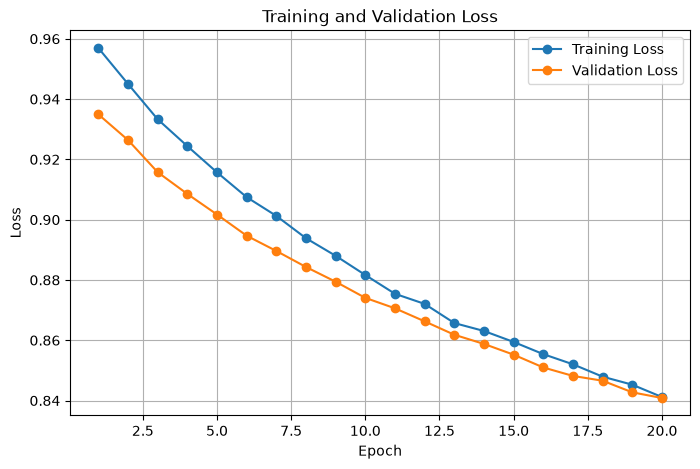

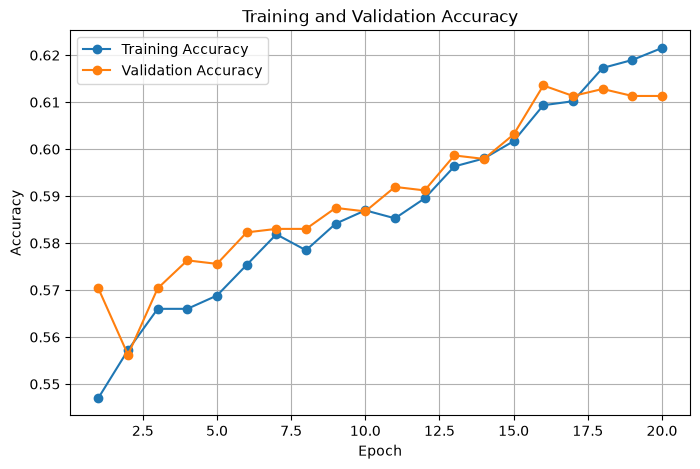

In [13]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Saving the Text-Only BERT Model

In [14]:
import os
import json

os.makedirs("../results/text_only_bert", exist_ok=True)

# Save model weights
torch.save(
    model.state_dict(),
    "../results/text_only_bert/best_model.pth"
)

# Save training history
with open("../results/text_only_bert/training_history.json", "w") as f:
    json.dump(history, f, indent=4)

print("Model and training history saved successfully.")

Model and training history saved successfully.


### Final Test Evaluation

This cell evaluates the selected text-only BERT model on the test dataset. It calculates the final loss and accuracy to measure how well the model performs on previously unseen data.

In [15]:
test_loss, test_accuracy = evaluate(
    model, test_loader, criterion
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.8919
Test Accuracy: 0.5677


### Final Test Results

The trained text-only BERT model achieved a test accuracy of 56.77% and a test loss of 0.8919. The test accuracy was lower than the best validation accuracy of 61.36%, showing a difference in performance on unseen data. These results will be used as the baseline for comparison with the multimodal models.